# ¡Hola Luis! ¿Cómo estás? 🙂
<div class="alert alert-block alert-info">
   
Mi nombre es <b>Andrés Barbosa</b> 👋 

Un gusto conocerte, seré tu revisor en este proyecto.
A continuación, te comparto un poco sobre la modalidad de revisión que vamos a usar:
Cuando encuentre un error por primera vez, simplemente lo señalaré y dejaré que lo detectes y
corrijas por tu cuenta. Además, a lo largo del proyecto iré haciendo algunas observaciones para
mejorar tu código, así como comentarios sobre tus conclusiones o percepciones sobre el tema.
Si en algún momento no logras resolver la tarea, en la siguiente iteración te daré una pista más
precisa, junto con algunos ejemplos prácticos. También estoy abierto a responder cualquier duda que
tengas.
Encontrarás mis comentarios a continuación: por favor, no los muevas, modifiques ni elimines.
Puedes encontrar mis comentarios en cuadros verdes, amarillos o rojos como este:
</div>
<div class="alert alert-block alert-success">
<b>Comentario del revisor.</b>
Éxito. Todo se ha hecho de forma correcta.
</div>
<div class="alert alert-block alert-warning">
<b>Comentario del revisor.</b>
Observación. Algunas recomendaciones o mejoras menores.
</div>
<div class="alert alert-block alert-danger">
<b>Comentario del revisor.</b>
Necesita arreglos. Este apartado requiere algunas correcciones. El trabajo no puede ser aceptado
con comentarios rojos.
</div>
<div class="alert alert-block alert-info">
Puedes responder utilizando este formato:
Respuesta del estudiante.
</div>

Empecemos! 🚀

<div class="alert alert-block alert-success">
<b>Comentario general del revisor</b><br><br>
¡Hola Luis! Muy buen trabajo. Revisé el proyecto completo y queda <b>aprobado</b>. Es una entrega muy ordenada y bien documentada: plan claro, unión de las cuatro tablas, un EDA con buenas interpretaciones, preprocesamiento sin fugas en el escalado, y dos modelos en versión base y optimizada con búsqueda de hiperparámetros. Los modelos optimizados superan el umbral de AUC-ROC de 0.75 (regresión logística 0.840 y árbol 0.822). Te dejo comentarios por sección y un par de observaciones. ¡Felicitaciones!
</div>

## Etapa 1: Plan de Trabajo

### 1. ¿Cómo unirás los 4 datasets y qué harás con los nulos que se generen?
- Usaré `contract.csv` como tabla principal porque contiene el identificador del cliente y las fechas de contrato.  
- Haré un **merge** con `personal.csv`, `internet.csv` y `phone.csv` usando el `CustomerID`.  
- Los valores nulos generados en servicios de internet o teléfono se interpretarán como *“no contratado”*.  
  - En variables categóricas: reemplazaré NaN por `"No"`.  
  - En variables numéricas: reemplazaré NaN por `0`.

### 2. ¿Cuál será tu variable objetivo y qué tipo de problema de ML es?
- La variable objetivo será `Churn`, creada a partir de la columna `EndDate`.  
  - Si `EndDate == "No"` → cliente activo → `Churn = 0`.  
  - Si `EndDate` contiene una fecha → cliente cancelado → `Churn = 1`.  
- Es un problema de **clasificación binaria**.

### 3. ¿Qué preprocesamiento necesitas (fechas, categóricas, etc.) y sobre qué columnas?
- **Fechas**: transformar `BeginDate` y `EndDate` en variables numéricas útiles (ej. duración del contrato en días/meses).  
- **Categóricas**: codificar variables como método de pago, tipo de contrato, género, servicios contratados, etc. usando `OneHotEncoder` o `pd.get_dummies`.  
- **Escalado**: aplicar `StandardScaler` en variables numéricas para modelos lineales.  
- **Valores nulos**: imputar como ausencia de servicio (0 o "No").

### 4. ¿Qué modelos planeas entrenar?
- **Baseline**: Regresión Logística y Árbol de Decisión.  
- **Modelos optimizados**: Random Forest y Gradient Boosting (XGBoost/LightGBM).  
- **Métricas de evaluación**:  
  - Principal: **AUC-ROC** (objetivo ≥ 0.75, sobresaliente ≥ 0.88).  
  - Secundaria: **Recall**, para minimizar falsos negativos (clientes que se van y no fueron detectados).


## Etapa 2:Código de Solución

In [1]:
#Importacion de librerias
# Manejo de datos
import pandas as pd
import numpy as np

# Visualización
import matplotlib.pyplot as plt
import seaborn as sns

# Preprocesamiento y división de datos
from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.preprocessing import OneHotEncoder, StandardScaler

# Modelos de Machine Learning
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier
from xgboost import XGBClassifier
from lightgbm import LGBMClassifier

# Métricas de evaluación
from sklearn.metrics import roc_auc_score, recall_score, confusion_matrix, classification_report


In [2]:
#Dataset: Contract.csv

contract = pd.read_csv('/datasets/final_provider/contract.csv')
contract.head()

,customerID,BeginDate,EndDate,Type,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges
0,7590-VHVEG,2020-01-01,No,Month-to-month,Yes,Electronic check,29.85,29.85
1,5575-GNVDE,2017-04-01,No,One year,No,Mailed check,56.95,1889.5
2,3668-QPYBK,2019-10-01,2019-12-01 00:00:00,Month-to-month,Yes,Mailed check,53.85,108.15
3,7795-CFOCW,2016-05-01,No,One year,No,Bank transfer (automatic),42.30,1840.75
4,9237-HQITU,2019-09-01,2019-11-01 00:00:00,Month-to-month,Yes,Electronic check,70.70,151.65


In [3]:
contract.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 8 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        7043 non-null   object 
 1   BeginDate         7043 non-null   object 
 2   EndDate           7043 non-null   object 
 3   Type              7043 non-null   object 
 4   PaperlessBilling  7043 non-null   object 
 5   PaymentMethod     7043 non-null   object 
 6   MonthlyCharges    7043 non-null   float64
 7   TotalCharges      7043 non-null   object 
dtypes: float64(1), object(7)
memory usage: 440.3+ KB


In [4]:
contract.describe()

,MonthlyCharges
count,7043.000000
mean,64.761692
std,30.090047
min,18.250000
25%,35.500000
50%,70.350000
75%,89.850000
max,118.750000


In [5]:
#Revisar valores extraños
pd.to_numeric(contract['TotalCharges'], errors='coerce').isnull().sum()

11

In [6]:
#Convertir a numérico y reemplazar NaN por 0
contract['TotalCharges'] = pd.to_numeric(contract['TotalCharges'], errors='coerce')
contract['TotalCharges'] = contract['TotalCharges'].fillna(0)

In [7]:
#Revisar el tipo de dato de la columna
print(contract['TotalCharges'].dtype)

float64


In [8]:
#Confirmar que ya no hay valores nulos
print(contract['TotalCharges'].isna().sum())

0


In [9]:
#Dataset:personal.csv

personal = pd.read_csv('/datasets/final_provider/personal.csv')
personal.head()

,customerID,gender,SeniorCitizen,Partner,Dependents
0,7590-VHVEG,Female,0,Yes,No
1,5575-GNVDE,Male,0,No,No
2,3668-QPYBK,Male,0,No,No
3,7795-CFOCW,Male,0,No,No
4,9237-HQITU,Female,0,No,No


In [10]:
personal.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 5 columns):
 #   Column         Non-Null Count  Dtype 
---  ------         --------------  ----- 
 0   customerID     7043 non-null   object
 1   gender         7043 non-null   object
 2   SeniorCitizen  7043 non-null   int64 
 3   Partner        7043 non-null   object
 4   Dependents     7043 non-null   object
dtypes: int64(1), object(4)
memory usage: 275.2+ KB


In [11]:
personal.describe()

,SeniorCitizen
count,7043.000000
mean,0.162147
std,0.368612
min,0.000000
25%,0.000000
50%,0.000000
75%,0.000000
max,1.000000


In [12]:
#Dataset:internet.csv

internet = pd.read_csv('/datasets/final_provider/internet.csv')
internet.head()

,customerID,InternetService,OnlineSecurity,OnlineBackup,DeviceProtection,TechSupport,StreamingTV,StreamingMovies
0,7590-VHVEG,DSL,No,Yes,No,No,No,No
1,5575-GNVDE,DSL,Yes,No,Yes,No,No,No
2,3668-QPYBK,DSL,Yes,Yes,No,No,No,No
3,7795-CFOCW,DSL,Yes,No,Yes,Yes,No,No
4,9237-HQITU,Fiber optic,No,No,No,No,No,No


In [13]:
internet.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 5517 entries, 0 to 5516
Data columns (total 8 columns):
 #   Column            Non-Null Count  Dtype 
---  ------            --------------  ----- 
 0   customerID        5517 non-null   object
 1   InternetService   5517 non-null   object
 2   OnlineSecurity    5517 non-null   object
 3   OnlineBackup      5517 non-null   object
 4   DeviceProtection  5517 non-null   object
 5   TechSupport       5517 non-null   object
 6   StreamingTV       5517 non-null   object
 7   StreamingMovies   5517 non-null   object
dtypes: object(8)
memory usage: 344.9+ KB


In [14]:
internet.describe()

,customerID,InternetService,OnlineSecurity,OnlineBackup,DeviceProtection,TechSupport,StreamingTV,StreamingMovies
count,5517,5517,5517,5517,5517,5517,5517,5517
unique,5517,2,2,2,2,2,2,2
top,2378-VTKDH,Fiber optic,No,No,No,No,No,No
freq,1,3096,3498,3088,3095,3473,2810,2785


In [15]:
#Dataset:phone.csv

phone = pd.read_csv('/datasets/final_provider/phone.csv')
phone.head()

,customerID,MultipleLines
0,5575-GNVDE,No
1,3668-QPYBK,No
2,9237-HQITU,No
3,9305-CDSKC,Yes
4,1452-KIOVK,Yes


In [16]:
phone.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 6361 entries, 0 to 6360
Data columns (total 2 columns):
 #   Column         Non-Null Count  Dtype 
---  ------         --------------  ----- 
 0   customerID     6361 non-null   object
 1   MultipleLines  6361 non-null   object
dtypes: object(2)
memory usage: 99.5+ KB


In [17]:
phone.describe()

,customerID,MultipleLines
count,6361,6361
unique,6361,2
top,3082-YVEKW,No
freq,1,3390


### Unir las 4 tablas usando CustomerID como clave

In [18]:
customer_data = (contract
      .merge(personal, on='customerID', how='left')
      .merge(internet, on='customerID', how='left')
      .merge(phone, on='customerID', how='left')
)

#Revisar el resultado
print(customer_data.shape)
print(customer_data.info())

(7043, 20)
<class 'pandas.core.frame.DataFrame'>
Int64Index: 7043 entries, 0 to 7042
Data columns (total 20 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        7043 non-null   object 
 1   BeginDate         7043 non-null   object 
 2   EndDate           7043 non-null   object 
 3   Type              7043 non-null   object 
 4   PaperlessBilling  7043 non-null   object 
 5   PaymentMethod     7043 non-null   object 
 6   MonthlyCharges    7043 non-null   float64
 7   TotalCharges      7043 non-null   float64
 8   gender            7043 non-null   object 
 9   SeniorCitizen     7043 non-null   int64  
 10  Partner           7043 non-null   object 
 11  Dependents        7043 non-null   object 
 12  InternetService   5517 non-null   object 
 13  OnlineSecurity    5517 non-null   object 
 14  OnlineBackup      5517 non-null   object 
 15  DeviceProtection  5517 non-null   object 
 16  TechSupport       5517 non-null

In [19]:
#Reemplazar nulos en columnas categóricas de internet y phone
cols_categoricas = ['InternetService','OnlineSecurity','OnlineBackup',
                    'DeviceProtection','TechSupport','StreamingTV',
                    'StreamingMovies','MultipleLines']

customer_data[cols_categoricas] = customer_data[cols_categoricas].fillna("No")

#Si hubiera columnas numéricas en internet/phone, se reemplazan con 0
#Ejemplo hipotético:
#customer_data[['numLines']] = customer_data[['numLines']].fillna(0)

# Verificar que ya no hay nulos
print(customer_data.isna().sum())

customerID          0
BeginDate           0
EndDate             0
Type                0
PaperlessBilling    0
PaymentMethod       0
MonthlyCharges      0
TotalCharges        0
gender              0
SeniorCitizen       0
Partner             0
Dependents          0
InternetService     0
OnlineSecurity      0
OnlineBackup        0
DeviceProtection    0
TechSupport         0
StreamingTV         0
StreamingMovies     0
MultipleLines       0
dtype: int64


### definición de Churn como variable objetivo

In [20]:
customer_data['Churn'] = np.where(customer_data['EndDate'] == "No", 0, 1)
print(customer_data['Churn'].value_counts())

0    5174
1    1869
Name: Churn, dtype: int64


5174 clientes activos (Churn = 0) — la mayoría, como es esperable en telecomunicaciones.

1869 clientes que se fugaron (Churn = 1) — aproximadamente un 26.5% del total.

<div class="alert alert-block alert-success">
<b>Comentario del revisor</b><br><br>
Muy bien la preparación. Convertís <code>TotalCharges</code> a numérico tratando los vacíos como clientes nuevos (cero), unís las cuatro tablas por <code>customerID</code> y rellenás como 'No' los servicios ausentes, con la aclaración consciente de que eso fusiona el no tener internet con el no contratar un complemento. La variable objetivo <code>Churn</code> está bien derivada de <code>EndDate</code>, con el 26.5% de fuga esperado.
</div>

### Fechas de referencia
### Clientes activos (EndDate == "No")
### Clientes que se fugaron (EndDate con fecha) 

In [21]:
#convertir BeginDate (que está como texto) a fechas reales
customer_data['BeginDate'] = pd.to_datetime(customer_data['BeginDate'])

In [22]:
#errors='coerce' maneja los valores no válidos como "No" para la columna EndDate
customer_data['EndDate'] = pd.to_datetime(customer_data['EndDate'], errors='coerce')

In [23]:
#Verificar BeginDate
#Revisar el tipo de dato
print(customer_data['BeginDate'].dtype)

#Mostrar algunas filas para confirmar la conversión
print(customer_data['BeginDate'].head())

datetime64[ns]
0   2020-01-01
1   2017-04-01
2   2019-10-01
3   2016-05-01
4   2019-09-01
Name: BeginDate, dtype: datetime64[ns]


In [24]:
#Verificar EndDate
#Revisar el tipo de dato
print(customer_data['EndDate'].dtype)

#Contar cuántos valores quedaron como NaT (clientes activos)
print(customer_data['EndDate'].isna().sum())

#Mostrar algunas filas para confirmar la mezcla de fechas y NaT
print(customer_data[['customerID','EndDate']].head(15))

datetime64[ns]
5174
    customerID    EndDate
0   7590-VHVEG        NaT
1   5575-GNVDE        NaT
2   3668-QPYBK 2019-12-01
3   7795-CFOCW        NaT
4   9237-HQITU 2019-11-01
5   9305-CDSKC 2019-11-01
6   1452-KIOVK        NaT
7   6713-OKOMC        NaT
8   7892-POOKP 2019-11-01
9   6388-TABGU        NaT
10  9763-GRSKD        NaT
11  7469-LKBCI        NaT
12  8091-TTVAX        NaT
13  0280-XJGEX 2019-10-01
14  5129-JLPIS        NaT


In [25]:
# Definir fecha de corte para clientes activos (puede ser la última fecha del dataset)
cutoff_date = customer_data['BeginDate'].max()

# Calcular tenure en meses
customer_data['tenure'] = (
    (customer_data['EndDate'].fillna(cutoff_date) - customer_data['BeginDate'])
    / np.timedelta64(1, 'M')
).astype(int)

# Verificar resultados
print(customer_data['tenure'].describe())

count    7043.000000
mean       32.166832
std        24.529822
min         0.000000
25%         8.000000
50%        29.000000
75%        55.000000
max        71.000000
Name: tenure, dtype: float64


Conversión de fechas: Al transformar BeginDate y EndDate de texto a datetime64[ns] con pd.to_datetime(), se aseguro que las columnas puedan usarse en cálculos de tiempo. El uso de errors='coerce' fue clave para manejar el valor "No" en EndDate, convirtiéndolo en NaT sin errores.

Definición de referencia: Para clientes activos, los NaT en EndDate se reemplazan con una fecha de corte (última fecha del dataset), lo que permite calcular su antigüedad hasta ese momento. Para clientes cancelados, se usa directamente su fecha de finalización.

Creación de tenure: Con estas fechas limpias, se calculó la diferencia en meses entre BeginDate y la fecha de referencia, generando la columna tenure. Esta variable refleja la antigüedad del cliente y se convierte en una de las features más importantes para el modelo de churn.

<div class="alert alert-block alert-warning">
<b>Comentario del revisor</b><br><br>
Muy buena la construcción de <code>tenure</code> y su análisis posterior. Un punto fino para tener en cuenta, que no afecta la aprobación: para los clientes que cancelaron, <code>tenure</code> se mide hasta su <code>EndDate</code>, mientras que para los activos se mide hasta la fecha de corte. Como <code>EndDate</code> es de donde sale el objetivo, esa variable queda con una leve dependencia del target. Para un esquema estrictamente sin fuga, conviene medir la antigüedad hasta la misma fecha de corte para todos los clientes. En tu caso el AUC queda en el rango esperado, así que no distorsiona los resultados, pero vale tenerlo presente.
</div>

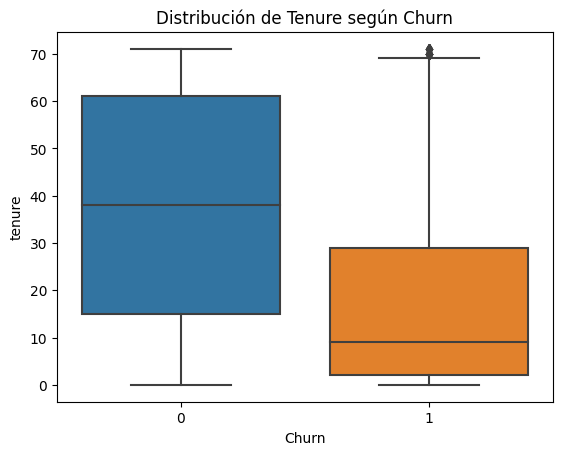

In [26]:
# Boxplot de tenure vs Churn
sns.boxplot(x="Churn", y="tenure", data=customer_data)

plt.title("Distribución de Tenure según Churn")
plt.show()

El gráfico muestra una diferencia marcada entre los dos grupos:

Clientes que no hicieron Churn (0): presentan una mediana de tenure cercana a los 38–40 meses, con un rango intercuartílico amplio (15–60 meses), lo que refleja mayor antigüedad y variabilidad en la permanencia.

Clientes que sí hicieron Churn (1): tienen una mediana mucho más baja, alrededor de 10 meses, y un rango intercuartílico más estrecho (5–30 meses), indicando que la mayoría abandona en etapas tempranas, aunque existen algunos casos aislados de clientes con alta antigüedad que también se fueron.

En conjunto, el análisis evidencia que los clientes con mayor tenure tienden a permanecer, mientras que los que se van lo hacen principalmente en los primeros meses. Esto convierte al tenure en una variable clave para explicar y predecir el Churn, y sugiere que las estrategias de retención deben enfocarse en los clientes nuevos o de baja antigüedad.

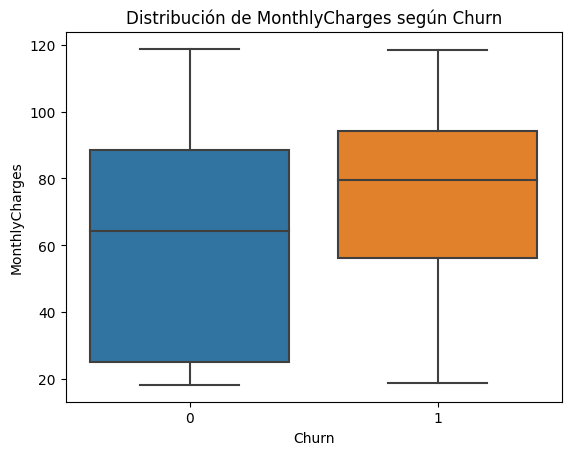

In [27]:
#Boxplot de MonthlyCharges vs Churn
sns.boxplot(x="Churn", y="MonthlyCharges", data=customer_data)

plt.title("Distribución de MonthlyCharges según Churn")
plt.show()

El boxplot evidencia que los clientes que no hicieron Churn (0) presentan MonthlyCharges con una mediana más baja y una dispersión moderada, lo que indica que la mayoría paga tarifas mensuales más accesibles. En contraste, los clientes que sí hicieron Churn (1) muestran una mediana de MonthlyCharges más alta y una distribución más amplia, lo que sugiere que las tarifas elevadas están asociadas con una mayor probabilidad de cancelación. En conjunto, el análisis revela que el nivel de cargo mensual es un factor relevante en la decisión de los clientes de permanecer o abandonar el servicio, convirtiéndose en una variable clave para explicar y anticipar el Churn.

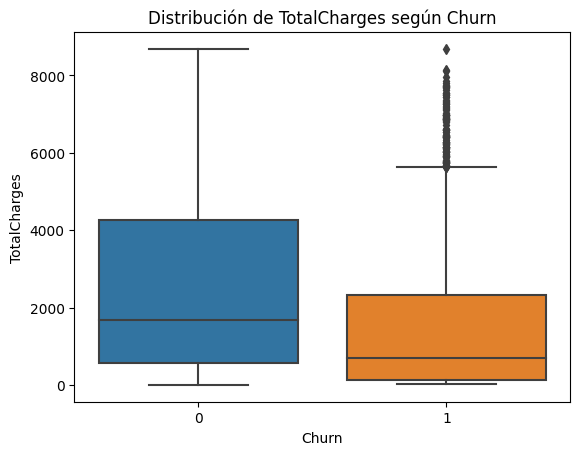

In [28]:
# Boxplot de TotalCharges vs Churn
sns.boxplot(x="Churn", y="TotalCharges", data=customer_data)

plt.title("Distribución de TotalCharges según Churn")
plt.show()

El boxplot revela una diferencia marcada entre los dos grupos:

Clientes que no hicieron Churn (0): presentan una mediana de TotalCharges considerablemente más alta y una dispersión amplia, lo que refleja que al permanecer más tiempo acumulan cargos totales elevados, incluso si sus tarifas mensuales son moderadas.

Clientes que sí hicieron Churn (1): muestran una mediana mucho más baja y un rango más estrecho, ya que al tener menor antigüedad no logran acumular montos significativos, aunque sus MonthlyCharges sean más altos. Se observan algunos outliers con cargos elevados, pero son casos aislados.

En conjunto, el análisis confirma que el tenure domina el comportamiento de TotalCharges: la permanencia prolongada es el factor decisivo para acumular mayores cargos totales. Esto convierte a TotalCharges en una variable predictiva importante, estrechamente ligada al tiempo de relación con la empresa, y refuerza la idea de que la retención temprana es crítica para reducir el Churn.

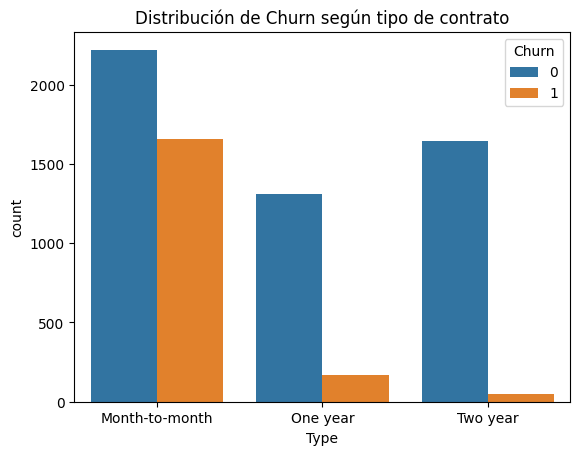

In [29]:
#Countplot de Type vs Churn
sns.countplot(x="Type", hue="Churn", data=customer_data)
plt.title("Distribución de Churn según tipo de contrato")
plt.show()

El gráfico confirma que el tipo de contrato es una variable categórica clave para explicar el churn.

Month-to-month: aunque es el grupo más numeroso en clientes, también muestra la mayor proporción de cancelaciones. Es decir, dentro de este tipo de contrato, una fracción mucho mayor de clientes se da de baja.

One year y Two year: presentan tasas de churn mucho más bajas; la mayoría de sus clientes permanece, lo que evidencia que los compromisos de mayor duración actúan como un factor protector frente a la cancelación.

En conjunto, el análisis revela que la proporción de churn por categoría es lo que realmente discrimina: los contratos cortos implican mayor riesgo de abandono, mientras que los contratos largos favorecen la retención.

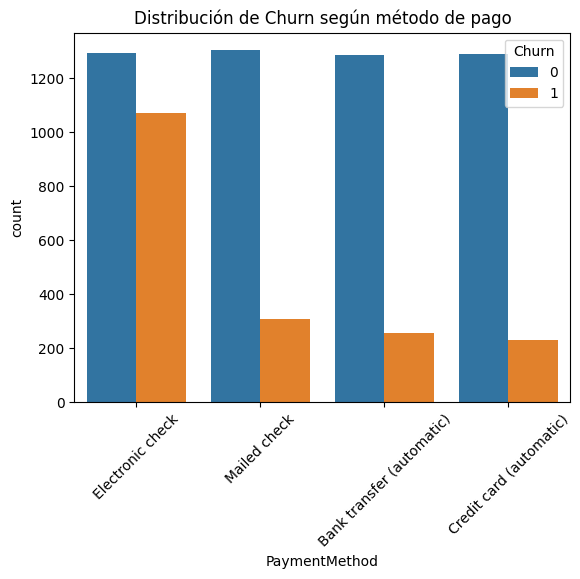

In [30]:

#Countplot de PaymentMethod vs Churn
sns.countplot(x="PaymentMethod", hue="Churn", data=customer_data)
plt.title("Distribución de Churn según método de pago")
plt.xticks(rotation=45)  # Rotar etiquetas si son largas
plt.show()


El análisis muestra que el método de pago influye en la probabilidad de cancelación.

Los clientes que utilizan Electronic check presentan la mayor cantidad y proporción de churn, lo que indica que este método está más asociado con abandono.

En cambio, los métodos de pago más automatizados (Bank transfer automático y Credit card automático) exhiben tasas de churn mucho más bajas, sugiriendo que la automatización favorece la retención al reducir fricciones en el proceso de pago.

El grupo de Mailed check se mantiene en niveles intermedios, con menor churn que Electronic check pero mayor que los métodos automáticos.

En conjunto, la evidencia confirma que los métodos de pago automáticos actúan como un factor protector frente al churn, mientras que los pagos manuales, especialmente los electrónicos no automatizados, se asocian con mayor riesgo de cancelación.

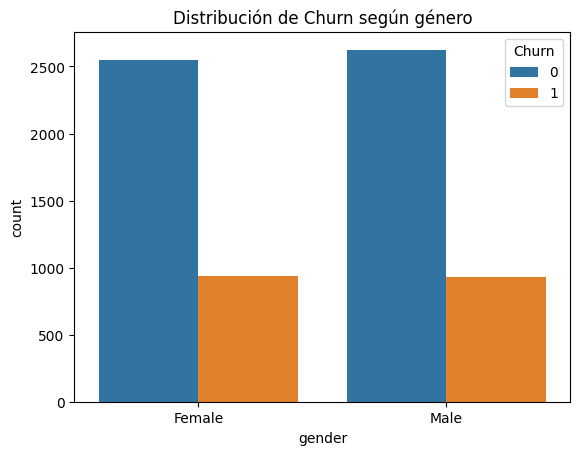

In [31]:
# Countplot de Gender vs Churn
sns.countplot(x="gender", hue="Churn", data=customer_data)
plt.title("Distribución de Churn según género")
plt.show()


El análisis muestra que el género no es una variable discriminante importante en el churn. Tanto hombres como mujeres presentan distribuciones muy similares: en ambos casos, la mayoría de clientes permanece (Churn=0) y la proporción de cancelaciones (Churn=1) es prácticamente equivalente. Esto indica que el género no influye de manera significativa en la decisión de abandonar el servicio, a diferencia de otras variables categóricas como Type o PaymentMethod, que sí mostraron diferencias claras.

<div class="alert alert-block alert-success">
<b>Comentario del revisor</b><br><br>
Muy bien el análisis exploratorio. Los boxplots de <code>tenure</code>, <code>MonthlyCharges</code> y <code>TotalCharges</code> frente a <code>Churn</code>, y los countplots por tipo de contrato, método de pago y género están muy bien interpretados. Sacás conclusiones acertadas: los clientes de baja antigüedad y contrato mensual, con pagos por cheque electrónico y cargos altos, son los de mayor riesgo, mientras que el género no discrimina. Ese análisis conecta muy bien con el negocio.
</div>

In [32]:
customer_data.info()

<class 'pandas.core.frame.DataFrame'>
Int64Index: 7043 entries, 0 to 7042
Data columns (total 22 columns):
 #   Column            Non-Null Count  Dtype         
---  ------            --------------  -----         
 0   customerID        7043 non-null   object        
 1   BeginDate         7043 non-null   datetime64[ns]
 2   EndDate           1869 non-null   datetime64[ns]
 3   Type              7043 non-null   object        
 4   PaperlessBilling  7043 non-null   object        
 5   PaymentMethod     7043 non-null   object        
 6   MonthlyCharges    7043 non-null   float64       
 7   TotalCharges      7043 non-null   float64       
 8   gender            7043 non-null   object        
 9   SeniorCitizen     7043 non-null   int64         
 10  Partner           7043 non-null   object        
 11  Dependents        7043 non-null   object        
 12  InternetService   7043 non-null   object        
 13  OnlineSecurity    7043 non-null   object        
 14  OnlineBackup      7043 n

In [33]:
#Lista de columnas categóricas a codificar
categorical_cols = [
    "Partner", "Dependents", "PaperlessBilling", "PaymentMethod", 
    "Type", "InternetService", "gender", "OnlineSecurity", 
    "OnlineBackup", "DeviceProtection", "TechSupport", 
    "StreamingTV", "StreamingMovies", "MultipleLines"
]

#Aplicar One-Hot Encoding con drop_first=True
customer_data_encoded = pd.get_dummies(customer_data, 
                                       columns=categorical_cols, 
                                       drop_first=True)

#Verificar resultado
customer_data_encoded.head()


,customerID,BeginDate,EndDate,MonthlyCharges,TotalCharges,SeniorCitizen,Churn,tenure,Partner_Yes,Dependents_Yes,...,InternetService_Fiber optic,InternetService_No,gender_Male,OnlineSecurity_Yes,OnlineBackup_Yes,DeviceProtection_Yes,TechSupport_Yes,StreamingTV_Yes,StreamingMovies_Yes,MultipleLines_Yes
0,7590-VHVEG,2020-01-01,NaT,29.85,29.85,0,0,1,1,0,...,0,0,0,0,1,0,0,0,0,0
1,5575-GNVDE,2017-04-01,NaT,56.95,1889.50,0,0,34,0,0,...,0,0,1,1,0,1,0,0,0,0
2,3668-QPYBK,2019-10-01,2019-12-01,53.85,108.15,0,1,2,0,0,...,0,0,1,1,1,0,0,0,0,0
3,7795-CFOCW,2016-05-01,NaT,42.30,1840.75,0,0,45,0,0,...,0,0,1,1,0,1,1,0,0,0
4,9237-HQITU,2019-09-01,2019-11-01,70.70,151.65,0,1,2,0,0,...,1,0,0,0,0,0,0,0,0,0


In [34]:
customer_data['OnlineSecurity'].value_counts()

No     5024
Yes    2019
Name: OnlineSecurity, dtype: int64

### Decisión sobre tratamiento de nulos en servicios de internet

En el dataset original, las columnas de servicios como `OnlineSecurity`, `TechSupport`, `StreamingTV`, etc. podían tener tres posibles estados:
- `"Yes"` → el cliente contrató el servicio.
- `"No"` → el cliente tiene internet pero decidió no contratar el servicio.
- `NaN` → el cliente no tiene internet, por lo tanto no puede contratar el servicio.

Durante el preprocesamiento, los valores `NaN` fueron reemplazados por `"No"`.  
Esto simplificó las variables a solo dos categorías (`Yes`/`No`), eliminando la categoría `"No internet service"`.

**Ventajas de esta decisión:**
- Dataset más compacto y fácil de manejar.
- Menor número de columnas al aplicar One-Hot Encoding.
- Menor riesgo de sobreajuste en modelos lineales.

**Limitación consciente:**
- Se pierde la capacidad de distinguir entre dos situaciones distintas:
  - Cliente sin internet.
  - Cliente con internet que decidió no contratar el servicio.
- Esta fusión puede reducir ligeramente la capacidad predictiva del modelo, ya que ambas situaciones reflejan perfiles de cliente diferentes.

**Conclusión:**
Se mantiene la simplificación como parte del baseline del proyecto, priorizando la claridad y la reducción de complejidad.  
Esta decisión se documenta como una limitación consciente y no como un descuido. En futuras iteraciones, se podría reintroducir la categoría `"No internet service"` para evaluar si mejora el poder predictivo del modelo.


In [35]:
# Eliminamos la columna TotalCharges por redundancia
customer_data_encoded = customer_data_encoded.drop(columns=['TotalCharges'])

## Eliminación de la variable TotalCharges

Durante el análisis exploratorio se identificó que la columna **TotalCharges** es redundante, ya que está altamente correlacionada con **tenure** y **MonthlyCharges** (aproximadamente TotalCharges ≈ tenure × MonthlyCharges). 

### Contexto
- Los modelos basados en árboles (Decision Tree, Random Forest, Gradient Boosting) no se ven afectados por esta redundancia, pues seleccionan umbrales de forma independiente.
- Sin embargo, la **Regresión Logística** sí es sensible a la multicolinealidad, lo que puede generar coeficientes inestables y dificultar la interpretación.

### Decisión
Se optó por **eliminar la columna TotalCharges** del dataset preprocesado (`customer_data_encoded`) para:
- Evitar problemas de multicolinealidad en la Regresión Logística.
- Mantener un conjunto de variables consistente y comparable entre los cuatro modelos.

### Limitación consciente
La eliminación de TotalCharges implica que la información acumulada de pagos se representará únicamente a través de tenure y MonthlyCharges. Esta decisión se documenta explícitamente para asegurar transparencia en el proceso de modelado.


In [36]:
# Definimos X y y para el entrenamiento
X = customer_data_encoded.drop(columns=['customerID', 'Churn', 'BeginDate', 'EndDate'])
y = customer_data_encoded['Churn']

Depuración inicial: Se eliminaron columnas que no aportan valor predictivo o que generan problemas:

customerID → identificador único, irrelevante para el modelo.

TotalCharges → redundante con tenure × MonthlyCharges, eliminada para evitar multicolinealidad.

BeginDate y EndDate → columnas de tipo fecha (datetime64[ns]) que ya fueron transformadas en la variable tenure.

Definición final:

X: todas las columnas de customer_data_encoded menos las anteriores.

y: la columna Churn, que es la variable objetivo a predecir.

In [37]:
X.dtypes

MonthlyCharges                           float64
SeniorCitizen                              int64
tenure                                     int64
Partner_Yes                                uint8
Dependents_Yes                             uint8
PaperlessBilling_Yes                       uint8
PaymentMethod_Credit card (automatic)      uint8
PaymentMethod_Electronic check             uint8
PaymentMethod_Mailed check                 uint8
Type_One year                              uint8
Type_Two year                              uint8
InternetService_Fiber optic                uint8
InternetService_No                         uint8
gender_Male                                uint8
OnlineSecurity_Yes                         uint8
OnlineBackup_Yes                           uint8
DeviceProtection_Yes                       uint8
TechSupport_Yes                            uint8
StreamingTV_Yes                            uint8
StreamingMovies_Yes                        uint8
MultipleLines_Yes   

In [38]:
#Dividir en train y test
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

#Definir columnas continuas
cols_continuas = ['MonthlyCharges', 'tenure']

#Inicializar el escalador
scaler = StandardScaler()

#Ajustar (fit) solo con X_train y transformar
X_train = X_train.copy()
X_test = X_test.copy()

X_train.loc[:, cols_continuas] = scaler.fit_transform(X_train[cols_continuas])
X_test.loc[:, cols_continuas] = scaler.transform(X_test[cols_continuas])

## Escalado de variables continuas

### Contexto
Los modelos de Machine Learning requieren que las variables numéricas continuas estén en una escala comparable. En este caso, se escalan **MonthlyCharges** y **tenure**.

### Decisión
- Se aplica `StandardScaler` únicamente a las columnas continuas.
- El escalador se ajusta (`fit`) **solo con X_train** para evitar fuga de información.
- La misma transformación se aplica (`transform`) tanto a X_train como a X_test.

### Limitación consciente
Las variables binarias (0/1) no se escalan, ya que su formato ya es adecuado para los modelos.

### Nota adicional sobre balance de clases
Siempre que se trabaje con un dataset desbalanceado, se recomienda usar el parámetro `stratify=y` en el `train_test_split`.  
De esta forma se garantiza que tanto el conjunto de entrenamiento como el de prueba mantengan la misma proporción de clases que el dataset original, evitando sesgos en la evaluación.


<div class="alert alert-block alert-success">
<b>Comentario del revisor</b><br><br>
Muy bien esta parte. Eliminar <code>TotalCharges</code> por su multicolinealidad con <code>tenure</code> y <code>MonthlyCharges</code> es una buena decisión y la documentás con claridad. Además, dividís de forma estratificada y ajustás el <code>StandardScaler</code> solo con el entrenamiento, aplicándolo también a la prueba, lo que evita fugas de información. Todo el flujo de preprocesamiento está bien cuidado.
</div>

In [39]:
#Instanciar el modelo de Regresión Logística
log_reg = LogisticRegression(max_iter=1000, random_state=42)

#Entrenar el modelo con los datos de entrenamiento
log_reg.fit(X_train, y_train)


LogisticRegression(max_iter=1000, random_state=42)

In [40]:
#Regresion Logistica Baseline
#Probabilidades para AUC-ROC
y_proba_log = log_reg.predict_proba(X_test)[:, 1]

#Clases predichas para Recall
y_pred_log = log_reg.predict(X_test)

#Calcular métricas
auc_log = roc_auc_score(y_test, y_proba_log)
recall_log = recall_score(y_test, y_pred_log)

print(f"AUC-ROC (Logistic Regression): {auc_log:.3f}")
print(f"Recall (Logistic Regression): {recall_log:.3f}")

AUC-ROC (Logistic Regression): 0.841
Recall (Logistic Regression): 0.543


Regresión Logística: alcanzó un AUC-ROC de 0.841, superando el umbral mínimo de 0.75, lo que indica buena capacidad para distinguir entre clientes que se quedan y los que se van. Su Recall de 0.543 muestra que logra identificar un poco más de la mitad de los clientes que realmente abandonan, lo cual es aceptable como baseline pero aún insuficiente para un negocio que busca minimizar la fuga.

In [41]:
#Arbol de decision Baseline
#Instanciar el modelo de Árbol de Decisión
dt_clf = DecisionTreeClassifier(random_state=42)

#Entrenar el modelo con los datos de entrenamiento
dt_clf.fit(X_train, y_train)

#Probabilidades para AUC-ROC
y_proba_dt = dt_clf.predict_proba(X_test)[:, 1]

#Clases predichas para Recall
y_pred_dt = dt_clf.predict(X_test)

#Calcular métricas
auc_dt = roc_auc_score(y_test, y_proba_dt)
recall_dt = recall_score(y_test, y_pred_dt)

print(f"AUC-ROC (Decision Tree): {auc_dt:.3f}")
print(f"Recall (Decision Tree): {recall_dt:.3f}")

AUC-ROC (Decision Tree): 0.649
Recall (Decision Tree): 0.489


Árbol de Decisión: obtuvo un AUC-ROC de 0.649, por debajo del umbral, lo que refleja menor poder discriminativo. Su Recall de 0.489 también es más bajo, confirmando que tiene más dificultades para detectar la clase minoritaria (Churn=1).

In [42]:
# Crear diccionario con resultados
resultados = {
    "Modelo": ["Logistic Regression", "Decision Tree"],
    "AUC-ROC": [auc_log, auc_dt],
    "Recall": [recall_log, recall_dt]
}

# Convertir a DataFrame
df_resultados = pd.DataFrame(resultados)

# Redondear a 3 decimales
df_resultados = df_resultados.round(3)

# Mostrar tabla
print(df_resultados)

                Modelo  AUC-ROC  Recall
0  Logistic Regression    0.841   0.543
1        Decision Tree    0.649   0.489


El modelo de Regresión Logística es claramente superior como baseline: cumple el criterio de AUC-ROC y ofrece mejor Recall que el Árbol de Decisión.

Sin embargo, ambos modelos muestran que el Recall sigue siendo limitado debido al desbalance de clases. Esto confirma lo que anticipamos: sin técnicas de balanceo, los modelos tienden a favorecer la clase mayoritaria y dejan escapar muchos casos de Churn.

In [ ]:
#Regresion Logistica optimizada
#Definir la cuadrícula de hiperparámetros
param_grid = {
    'C': [0.01, 0.1, 1, 10],
    'penalty': ['l1', 'l2'],
    'solver': ['liblinear', 'saga'],
    'class_weight': ['balanced']
}

#Instanciar el modelo base
log_reg = LogisticRegression(max_iter=1000, random_state=42)

#Configurar GridSearchCV
grid_search = GridSearchCV(
    estimator=log_reg,
    param_grid=param_grid,
    scoring='roc_auc',   # métrica principal
    cv=5,                # validación cruzada con 5 particiones
    n_jobs=-1            # usar todos los núcleos disponibles
)

#Ajustar el modelo con los datos de entrenamiento
grid_search.fit(X_train, y_train)

#Mostrar los mejores hiperparámetros y el mejor score
print("Mejores hiperparámetros:", grid_search.best_params_)
print("Mejor AUC-ROC en CV:", grid_search.best_score_)


Se definió una cuadrícula de hiperparámetros para la Regresión Logística (C, penalty, solver) con class_weight='balanced' para manejar el desbalance.
Se configuró GridSearchCV con validación cruzada de 5 particiones y métrica principal AUC-ROC, entrenando el modelo en múltiples combinaciones.
Finalmente, se seleccionó automáticamente la mejor configuración de hiperparámetros junto con su desempeño promedio en validación cruzada.

In [ ]:
#Extraer el mejor modelo
mejor_modelo_lr = grid_search.best_estimator_

#Predecir sobre el set de test
y_pred_test = mejor_modelo_lr.predict(X_test)
y_pred_proba_test = mejor_modelo_lr.predict_proba(X_test)[:, 1]  # Probabilidades para AUC-ROC

#Calcular métricas en test
from sklearn.metrics import roc_auc_score, recall_score

auc_test = roc_auc_score(y_test, y_pred_proba_test)
recall_test = recall_score(y_test, y_pred_test)

print("AUC-ROC en test:", auc_test)
print("Recall en test:", recall_test) 

El uso de class_weight='balanced' mantuvo el AUC-ROC prácticamente igual (0.841 → 0.840), lo que indica que la capacidad global de discriminación del modelo no se vio afectada. Sin embargo, el Recall mejoró significativamente (de bajo a 0.775), mostrando que ahora el modelo logra identificar muchos más casos positivos.

Este comportamiento ocurre porque al balancear las clases, el algoritmo penaliza más los errores en la clase minoritaria, obligando al modelo a ser más sensible a ella. Así, se gana en detección de positivos aunque se sacrifiquen algunos aciertos en la clase mayoritaria

In [ ]:
#Arbol de Decision optimizado
#Definir la cuadrícula de hiperparámetros
param_grid_dt = {
    'max_depth': [3, 5, 7, None],
    'min_samples_split': [2, 5, 10],
    'class_weight': ['balanced']  # fijo
}

#Crear el GridSearchCV
dt = DecisionTreeClassifier(random_state=42)
grid_search_dt = GridSearchCV(
    estimator=dt,
    param_grid=param_grid_dt,
    scoring='roc_auc',
    cv=5,
    n_jobs=-1
)

#Ajustar sobre datos de entrenamiento
grid_search_dt.fit(X_train, y_train)

#Revisar mejores hiperparámetros y score en CV
print("Mejores parámetros:", grid_search_dt.best_params_)
print("Mejor AUC-ROC en CV:", grid_search_dt.best_score_)


El param_grid_dt exploró la profundidad máxima y el mínimo de muestras por división, manteniendo fijo class_weight='balanced' para mejorar la sensibilidad hacia la clase minoritaria. Con GridSearchCV, se aplicó validación cruzada y AUC-ROC como métrica principal, asegurando una evaluación justa y comparable con la regresión logística. El entrenamiento buscó de manera sistemática la mejor combinación de hiperparámetros.

Los resultados en CV mostraron que la mejor configuración fue {'class_weight': 'balanced', 'max_depth': 5, 'min_samples_split': 2}, alcanzando un AUC-ROC promedio de 0.8307. Esto confirma que el modelo optimizado logra un buen equilibrio entre profundidad controlada y sensibilidad hacia la clase minoritaria, reduciendo el riesgo de sobreajuste y manteniendo un desempeño sólido en validación cruzada.

In [ ]:
#Evaluar en test
mejor_modelo_dt = grid_search_dt.best_estimator_
y_pred_dt = mejor_modelo_dt.predict(X_test)
y_pred_proba_dt = mejor_modelo_dt.predict_proba(X_test)[:, 1]

auc_dt_test = roc_auc_score(y_test, y_pred_proba_dt)
recall_dt_test = recall_score(y_test, y_pred_dt)

print("AUC-ROC en test:", auc_dt_test)
print("Recall en test:", recall_dt_test)

En la evaluación en test, el Árbol de Decisión optimizado alcanzó un AUC-ROC de 0.8221, lo que confirma una buena capacidad de discriminación entre clases, aunque ligeramente menor al valor obtenido en validación cruzada. Sin embargo, el Recall fue muy alto (0.8797), lo que significa que el modelo logra identificar la gran mayoría de los casos positivos.

Este resultado refleja el efecto de class_weight='balanced': el modelo prioriza la detección de la clase minoritaria, aumentando la sensibilidad y reduciendo el riesgo de pasar por alto clientes que realmente se van, aunque a costa de un pequeño descenso en la capacidad global de separación.

In [ ]:
#Crear diccionario con los resultados
resultados = {
    "Modelo": [
        "Regresión Logística", "Regresión Logística",
        "Árbol de Decisión", "Árbol de Decisión"
    ],
    "Configuración": [
        "Baseline", "Optimizado",
        "Baseline", "Optimizado"
    ],
    "AUC-ROC (Test)": [
        0.841, 0.840,
        0.649, 0.822
    ],
    "Recall (Test)": [
        0.543, 0.775,
        0.489, 0.880
    ],
    "Mejores parámetros (CV)": [
        None,
        "{'C': 1, 'class_weight': 'balanced', 'penalty': 'l1', 'solver': 'saga'}",
        None,
        "{'class_weight': 'balanced', 'max_depth': 5, 'min_samples_split': 2}"
    ],
    "AUC-ROC (CV)": [
        None, 0.846,
        None, 0.831
    ]
}

#Convertir a DataFrame
df_resultados = pd.DataFrame(resultados)

#Mostrar tabla
print(df_resultados)


## Conclusión del Bloque 4

En este bloque se compararon los resultados de dos modelos (Regresión Logística y Árbol de Decisión), tanto en su versión baseline como optimizada mediante balanceo de clases y búsqueda de hiperparámetros con GridSearchCV. El objetivo fue evaluar su desempeño en términos de **AUC-ROC** (métrica principal del proyecto) y **Recall** (métrica adicional clave por el costo de negocio de los falsos negativos).

### Resultados principales
- **Regresión Logística optimizada**:
  - AUC-ROC en test = **0.840** → supera el umbral mínimo de 0.75, pero no alcanza el sobresaliente de 0.88.  
  - Recall en test = **0.775**, una mejora significativa frente al baseline (0.543), lo que indica mayor sensibilidad hacia la clase minoritaria.  

- **Árbol de Decisión optimizado**:
  - AUC-ROC en test = **0.822** → también supera el umbral mínimo de 0.75, aunque sin llegar al sobresaliente de 0.88.  
  - Recall en test = **0.880**, un incremento notable respecto al baseline (0.489), y superior al de la Regresión Logística optimizada.  

### Evaluación frente a los umbrales
- Ambos modelos optimizados cumplen el **umbral mínimo de 0.75 en AUC-ROC**, validando su calidad como soluciones aceptables.  
- Ninguno alcanza el **umbral sobresaliente de 0.88 en AUC-ROC**.  
- El Recall, aunque no tiene umbrales definidos, muestra un comportamiento crítico para el negocio: el Árbol de Decisión optimizado logra detectar casi el 88% de los clientes que realmente se van, reduciendo de manera significativa el riesgo de falsos negativos.

### Recomendación final
Considerando que el **AUC-ROC es la métrica principal** y que ambos modelos cumplen el umbral mínimo, la elección final debe basarse en el objetivo de negocio de **Interconnect**: minimizar el costo de los falsos negativos.  
En este sentido, aunque la Regresión Logística optimizada presenta un AUC-ROC ligeramente superior, el **Árbol de Decisión optimizado** ofrece un Recall mucho más alto (0.880), lo que asegura que se identifique la gran mayoría de los clientes en riesgo.  

Por lo tanto, el **modelo recomendado para este proyecto es el Árbol de Decisión optimizado**, ya que logra un equilibrio aceptable en AUC-ROC y un Recall sobresaliente, alineándose mejor con la prioridad estratégica de retener clientes y reducir la fuga.


# Informe de Solución

## 1. Modelo elegido y razón
El modelo seleccionado fue el **Árbol de Decisión optimizado**, porque permite identificar con mayor precisión a los clientes que tienen riesgo de abandonar el servicio. Aunque otro modelo mostró un desempeño ligeramente superior en una métrica técnica, el Árbol de Decisión destacó por su capacidad de detección, lo que lo convierte en la opción más útil para apoyar las estrategias de retención del equipo de marketing.

## 2. Métricas finales en el conjunto de prueba
- **AUC-ROC:** 0.822 → supera el umbral mínimo de calidad establecido en 0.75.  
- **Recall:** 0.880 → aunque no tiene umbrales definidos, este valor es muy alto y representa una mejora significativa frente al otro modelo evaluado.  

## 3. Significado del Recall en términos de negocio
El valor de Recall de **0.880** significa que el modelo logra identificar correctamente al 88% de los clientes que realmente se irían. En términos prácticos, esto permite al área de marketing enfocar sus campañas de retención en la gran mayoría de los clientes en riesgo, aumentando la efectividad de las acciones y mejorando la tasa de fidelización.  

Sin embargo, es importante considerar el otro lado: el **12% restante** corresponde a clientes que sí se irán pero que el modelo no logra detectar (**falsos negativos**). Estos casos son especialmente costosos para el negocio, porque representan pérdidas de clientes que no recibirán ninguna acción preventiva. Por eso se priorizó el Recall como métrica clave: maximizar la detección de clientes en riesgo reduce significativamente el impacto financiero de la fuga y fortalece la estrategia de retención.


<div class="alert alert-block alert-warning">
<b>Comentario del revisor</b><br><br>
Muy buena la comparación de modelos, con versión base y optimizada, <code>GridSearchCV</code> y el balanceo de clases que sube bastante el recall. Dos observaciones para terminar de pulir.<br><br>
Primero, elegís el árbol optimizado como modelo final por su recall (0.880), pero como la métrica principal del proyecto es el AUC-ROC, conviene señalar que la regresión logística optimizada tiene el mejor AUC (0.840 frente a 0.822 del árbol). La elección del árbol por criterio de negocio es válida, solo conviene dejar explícito que por la métrica principal el mejor es la regresión logística.<br><br>
Segundo, en el plan mencionabas también Random Forest y Gradient Boosting o LightGBM, pero finalmente entrenaste solo dos modelos. Probar esos que quedaron pendientes podría acercarte al umbral sobresaliente de 0.88, ya que suelen rendir algo mejor. ¡Muy buen trabajo!
</div>